# alftrade Demo

A pedagogical **A-share low-frequency cross-sectional trading system** (daily signal frequency). Factors are computed in one **polars-vectorized** pass, and the data is sourced through a single **swappable** layer — simulated (cached parquet) or real (daily-bar parquet) — so the downstream pipeline is identical either way.

**Data-source switch (top of the notebook):**
```
DATA_SOURCE = "simulated"          # cached parquet, generated on demand
# DATA_SOURCE = "/path/to/real"    # real daily-bar parquet-by-date
df = load_panel(DATA_SOURCE, ...)  →  long table (BAR_COLUMNS)
```
Everything below (factors → calibration → portfolio → risk) is unchanged.

**Sections:**
- §1–§2b: polars factor computation, cached simulated parquet, real-data ingest
- §3–§7: cross-sectional signals, Fama-MacBeth calibration, factor profiling
- §8–§12: portfolio rebalancing, equity, turnover, style exposure, hedge, risk


In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import os

from alftrade import (
    DailyBar, StockUniverse, generate_simulated_market, bars_to_frame, frame_to_bars,
    FACTOR_NAMES, compute_factor_panel, factor_panel_to_dict,
    Signal, TradingEngine,
    Position, Trade, Portfolio, CostModel, CompositeSignal,
    SignalAggregator, PortfolioManager,
    RiskManager, RiskConfig,
    Broker, ExecutionConfig, Trader,
    CalibrationResult, FactorCalibrator,
    FactorProfile, ModelProfile, FactorProfiler,
    HedgeManager, FuturesContract, compute_hedged_equity,
    load_simulated, load_real, load_panel, fetch_daily_to_parquet, resolve_symbols,
    pool_label, symbol_names, DEFAULT_SIMULATED_ROOT,
    ingest_parquet,
)

plt.rcParams["figure.dpi"] = 110
np.random.seed(42)

# ── Control panel: data source + factor-inspection switch ──
DATA_SOURCE = "data/real_daily"       # backtest (§6+): "simulated" | "data/real_daily"
VIEW_SOURCE = "data/real_daily" # §3 inspect: "simulated"(→ small panel) | a cache path
VIEW_SYMBOL = "000988.SZ"       # §3 stock to inspect: explicit symbol | None → auto
STOCK_POOL = "csi300:30"       # §2b pool: "csi300:N" | "market_cap:N" | "market_cap_small:N" | "industry:白酒" | [codes]
print("alftrade ready — backtest:", DATA_SOURCE, "| inspect:", VIEW_SOURCE, VIEW_SYMBOL)

alftrade ready — backtest: data/real_daily | inspect: data/real_daily 000988.SZ


---

# Part I — Factors & Signals

## 1. Vectorized Factor Computation (polars)

``compute_factor_panel`` takes a **long** DataFrame (one row per symbol×date) and
computes all 11 factors in a single pass using ``.over("symbol")`` window
expressions — no per-stock Python loops.

In [2]:
rows = [
    {"date": 1, "symbol": "A", "open": 100.0, "high": 101.0, "low": 99.0,
     "close": 100.5, "volume": 1000.0, "prev_close": 100.0, "market_return": 0.005},
    {"date": 2, "symbol": "A", "open": 100.5, "high": 102.0, "low": 100.0,
     "close": 101.5, "volume": 1200.0, "prev_close": 100.5, "market_return": -0.002},
    {"date": 3, "symbol": "A", "open": 101.5, "high": 103.0, "low": 101.0,
     "close": 102.0, "volume": 1500.0, "prev_close": 101.5, "market_return": 0.008},
    {"date": 1, "symbol": "B", "open": 50.0, "high": 50.5, "low": 49.5,
     "close": 50.2, "volume": 800.0, "prev_close": 50.0, "market_return": 0.005},
    {"date": 2, "symbol": "B", "open": 50.2, "high": 51.0, "low": 50.0,
     "close": 50.8, "volume": 900.0, "prev_close": 50.2, "market_return": -0.002},
    {"date": 3, "symbol": "B", "open": 50.8, "high": 51.5, "low": 50.5,
     "close": 51.0, "volume": 1100.0, "prev_close": 50.8, "market_return": 0.008},
]
print(compute_factor_panel(pl.DataFrame(rows)))

shape: (6, 13)
┌──────┬────────┬──────────────┬─────────────┬───┬─────────────┬────────┬────────────┬─────────────┐
│ date ┆ symbol ┆ daily_return ┆ overnight_r ┆ … ┆ volume_rati ┆ rsi_14 ┆ atr_pct_14 ┆ market_beta │
│ ---  ┆ ---    ┆ ---          ┆ eturn       ┆   ┆ o           ┆ ---    ┆ ---        ┆ ---         │
│ i64  ┆ str    ┆ f64          ┆ ---         ┆   ┆ ---         ┆ f64    ┆ f64        ┆ f64         │
│      ┆        ┆              ┆ f64         ┆   ┆ f64         ┆        ┆            ┆             │
╞══════╪════════╪══════════════╪═════════════╪═══╪═════════════╪════════╪════════════╪═════════════╡
│ 1    ┆ A      ┆ 0.005        ┆ 0.0         ┆ … ┆ 1.0         ┆ 0.0    ┆ 0.0199     ┆ 1.0         │
│ 2    ┆ A      ┆ 0.00995      ┆ 0.0         ┆ … ┆ 1.090909    ┆ 1.0    ┆ 0.019704   ┆ 1.0         │
│ 3    ┆ A      ┆ 0.004926     ┆ 0.0         ┆ … ┆ 1.216216    ┆ 1.0    ┆ 0.019608   ┆ 1.0         │
│ 1    ┆ B      ┆ 0.004        ┆ 0.0         ┆ … ┆ 1.0         ┆ 0.0    ┆ 0.

## 2. Simulated Data — Generated Once, Cached as Parquet

``load_simulated`` generates the panel, stores it as **parquet-by-date**, and
reuses the cache on later calls (with a notice).  The generation code lives in
``datasource.py``, isolated from this notebook.

In [3]:
df_small = load_simulated(root="data/simulated_small", n_stocks=5, n_days=120, seed=3)
print("Long table:", df_small.shape, "| columns:", len(df_small.columns))
print("Parquet files on disk:", sorted(os.listdir("data/simulated_small/marketdata"))[:4], "...")

# Second call → reuses the cache (no regeneration).
_ = load_simulated(root="data/simulated_small", n_stocks=5, n_days=120, seed=3)

[data] Using existing simulated data at 'data/simulated_small' (120 files)
Long table: (600, 14) | columns: 14
Parquet files on disk: ['20200101.parquet', '20200102.parquet', '20200103.parquet', '20200104.parquet'] ...
[data] Using existing simulated data at 'data/simulated_small' (120 files)


## 2b. Real A-share Data — Fetched Daily Bars

``fetch_daily_to_parquet`` fetches **real daily bars** from akshare, caches them
as parquet-by-date, and reuses the cache on later runs — symmetric with
``load_simulated``.  The stock pool is driven by the ``STOCK_POOL`` switch at
the top of the notebook:

* ``"csi300:30"`` — first 30 CSI300 constituents (default)
* ``"market_cap:30"`` — top 30 by total market cap (large-cap)
* ``"market_cap_small:30"`` — bottom 30 (small-cap)
* ``"industry:白酒"`` — all A-share stocks in an Eastmoney industry board
* ``["600519", "000001", ...]`` — an explicit list of 6-digit codes

Set ``DATA_SOURCE = "data/real_daily"`` to run the backtest (§6+) on this data.

In [4]:
import datetime
import glob

end = datetime.date.today().strftime("%Y%m%d")
start = (datetime.date.today() - datetime.timedelta(days=365)).strftime("%Y%m%d")

# ── 1. Resolve the stock pool (fall back to the cached pool on network error) ──
try:
    symbols = resolve_symbols(STOCK_POOL)
    label = pool_label(STOCK_POOL)
except Exception as e:
    print(f"[data] 股票池解析失败（{type(e).__name__}），改用缓存中的股票池 …")
    cached = sorted(glob.glob("data/real_daily/marketdata/*.parquet"))
    symbols = sorted(pl.read_parquet(cached[-1])["symbol"].str.slice(0, 6).unique().to_list())
    label = f"缓存中的股票池（原 {STOCK_POOL} 未解析成功）"

# ── 2. Display the pool (names degrade to "?" if the name source is down) ──
names = symbol_names(symbols)
print(f"股票池 [{label}]：{len(symbols)} 只")
for c in symbols:
    print(f"  {c:<10s} {names.get(c, '?')}")
print()

# ── 3. Fetch / load daily bars ──
real_df = fetch_daily_to_parquet(symbols, start, end, root="data/real_daily")
print(f"Fetched real daily bars: {real_df.shape} "
      f"({real_df['symbol'].n_unique()} stocks × {real_df['date'].n_unique()} dates)")
print(real_df[["date", "symbol", "close", "prev_close", "market_return"]].head(4))
print("Factors from real daily data:")
print(compute_factor_panel(real_df)
      [["date", "symbol", "daily_return", "volatility_20d", "market_beta"]].head(4))
print("\nTo backtest on real data: set DATA_SOURCE = 'data/real_daily' and re-run §6+.")

Please wait for a moment:   0%|          | 0/70 [00:00<?, ?it/s]

股票池 [沪深300成分股（前 30）]：30 只
  600118     中国卫星
  002532     天山铝业
  000988     华工科技
  000657     中钨高新
  301308     江波龙
  688072     拓荆科技
  002202     金风科技
  301165     锐捷网络
  002558     巨人网络
  688183     生益电子
  600221     海航控股
  002602     世纪华通
  002837     英维克
  600549     厦门钨业
  688521     芯原股份
  300450     先导智能
  001280     中国铀业
  002353     杰瑞股份
  601727     上海电气
  600930     华电新能
  603893     瑞芯微
  300476     胜宏科技
  600522     中天科技
  300803     指南针
  300251     光线传媒
  601456     国联民生
  300866     安克创新
  002625     光启技术
  601018     宁波港
  002384     东山精密

[data] Using existing real daily data at 'data/real_daily' (243 files)
Fetched real daily bars: (7198, 14) (30 stocks × 243 dates)
shape: (4, 5)
┌──────────┬───────────┬───────┬────────────┬───────────────┐
│ date     ┆ symbol    ┆ close ┆ prev_close ┆ market_return │
│ ---      ┆ ---       ┆ ---   ┆ ---        ┆ ---           │
│ i64      ┆ str       ┆ f64   ┆ f64        ┆ f64           │
╞══════════╪═══════════╪═══════╪════════════╪

## 3. Panel & Factor Evolution

Pick a panel with the ``VIEW_SOURCE`` switch and a stock with ``VIEW_SYMBOL``
(both at the top of the notebook), then watch that stock's factors evolve.
The default inspects a **real** stock from ``data/real_daily``; set
``VIEW_SOURCE = "simulated"`` to look at a simulated one.

In [5]:
# Resolve the panel to inspect (fall back to simulated if the cache is missing).
view_source = VIEW_SOURCE
if view_source != "simulated" and not os.path.isdir(view_source):
    print(f"[data] '{view_source}' not found — falling back to simulated.")
    view_source = "simulated"

if view_source == "simulated":
    bars_panel, uni_panel, _ = frame_to_bars(load_panel(
        "simulated", root="data/simulated_small", n_stocks=5, n_days=120, seed=3))
else:
    bars_panel, uni_panel, _ = frame_to_bars(load_panel(view_source))

dates = sorted(bars_panel)
sym = VIEW_SYMBOL if VIEW_SYMBOL in uni_panel.symbols else uni_panel.symbols[0]
factor_df = compute_factor_panel(bars_to_frame(bars_panel))
sym_df = factor_df.filter(pl.col("symbol") == sym).sort("date")
closes = [bars_panel[d][sym].close for d in dates]
history = {k: sym_df[k].to_list() for k in FACTOR_NAMES}
print(f"Inspecting {sym} over {len(dates)} days")

Inspecting 000988.SZ over 243 days


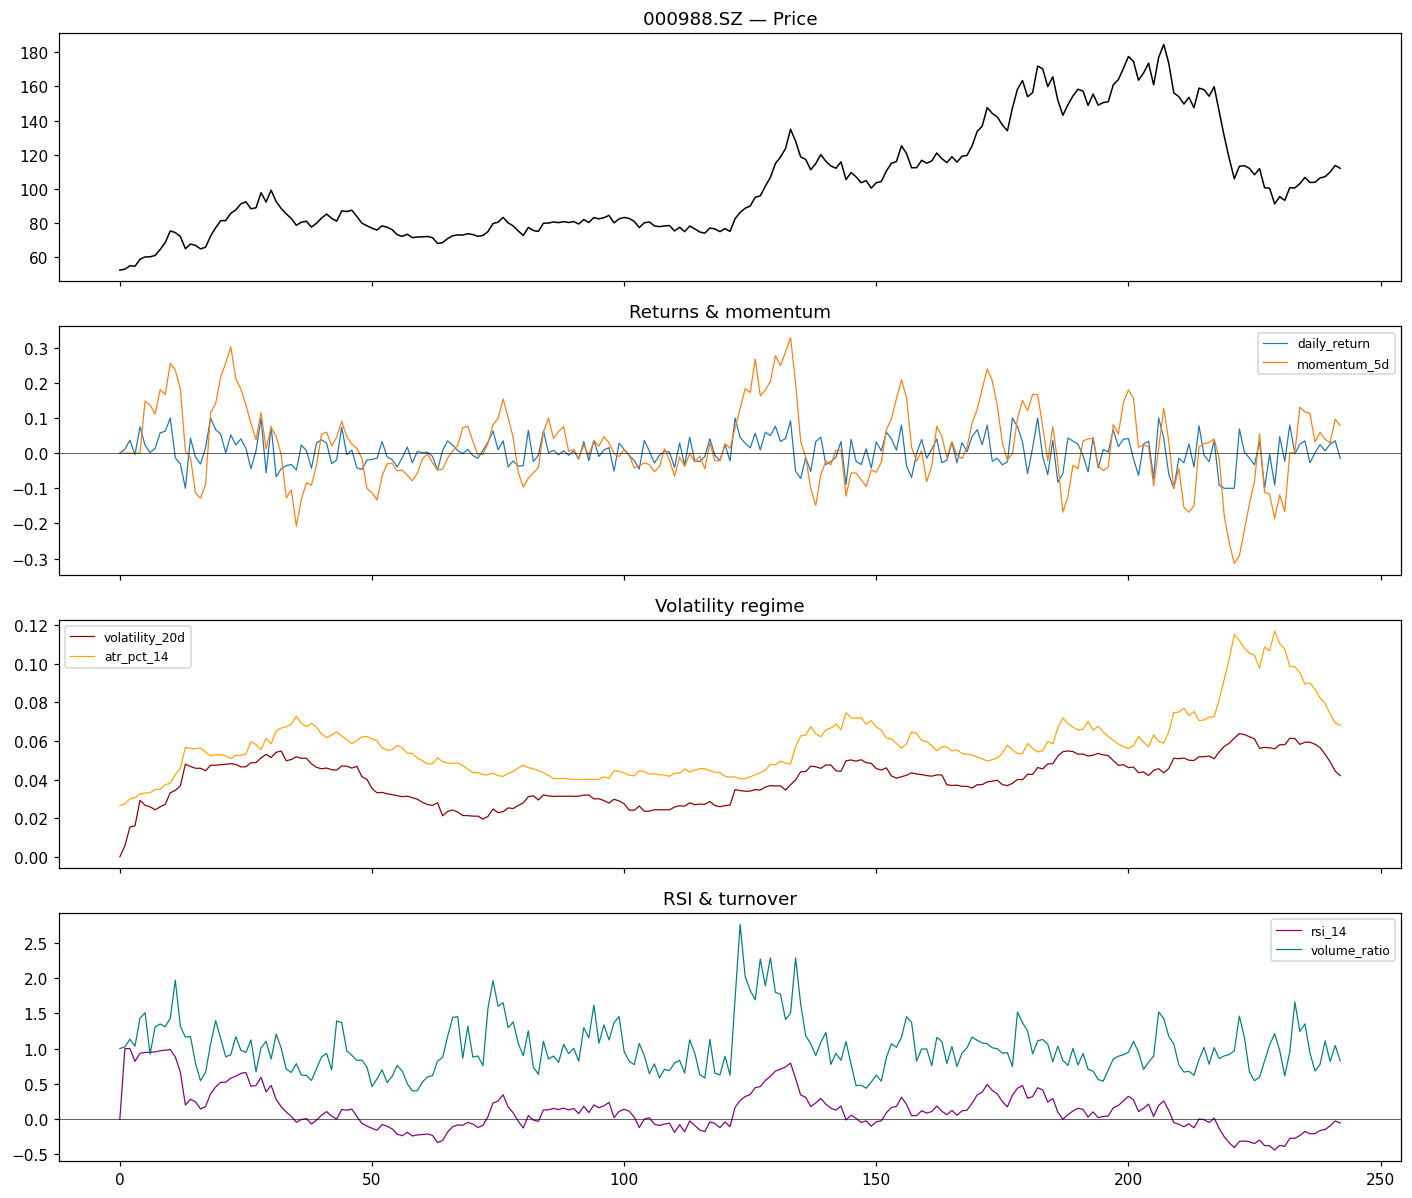

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
x = range(len(dates))
axes[0].plot(x, closes, lw=1.0, color="black"); axes[0].set_title(f"{sym} — Price")
axes[1].plot(x, history["daily_return"], lw=0.8, label="daily_return")
axes[1].plot(x, history["momentum_5d"], lw=0.8, label="momentum_5d")
axes[1].axhline(0, color="k", lw=0.4); axes[1].legend(fontsize=8)
axes[1].set_title("Returns & momentum")
axes[2].plot(x, history["volatility_20d"], lw=0.8, color="darkred", label="volatility_20d")
axes[2].plot(x, history["atr_pct_14"], lw=0.8, color="orange", label="atr_pct_14")
axes[2].legend(fontsize=8); axes[2].set_title("Volatility regime")
axes[3].plot(x, history["rsi_14"], lw=0.8, color="purple", label="rsi_14")
axes[3].plot(x, history["volume_ratio"], lw=0.8, color="teal", label="volume_ratio")
axes[3].axhline(0, color="k", lw=0.4); axes[3].legend(fontsize=8)
axes[3].set_title("RSI & turnover")
plt.tight_layout(); plt.show()

## 4. Cross-Sectional Standardization

In [7]:
factors_panel = factor_panel_to_dict(factor_df)
engine = TradingEngine(factors=factors_panel)
d = dates[-1]
cs = engine.build_cross_section(d, bars_panel[d])
print(f"Date {d}: {len(cs.symbols)} stocks")
for i, s in enumerate(cs.symbols[:4]):
    raw = cs.factors_by_symbol[s]["momentum_5d"]
    z = cs.z_matrix[i, FACTOR_NAMES.index("momentum_5d")]
    print(f"  {s:<12s}  raw={raw:+.6f}  z={z:+.4f}")

Date 20260818: 30 stocks
  000657.SZ     raw=+0.070286  z=+0.9103
  000988.SZ     raw=+0.078516  z=+1.0570
  001280.SZ     raw=+0.065217  z=+0.8200
  002202.SZ     raw=+0.104920  z=+1.5276


## 5. Signal Generation — Raw Mode

In [8]:
engine_raw = TradingEngine(factors=factors_panel, raw_thresholds={
    "momentum_5d": 0.02, "rsi_14": 0.30, "ma_dev_20": 0.02})
out = engine_raw.on_cross_section(d, bars_panel[d])
print(f"Date {d}: {len(out)} stocks have signals")
for sym, sigs in list(out.items())[:4]:
    for s in sigs:
        print(f"  {s}")

Date 20260818: 24 stocks have signals
  Signal(000657.SZ momentum_5d: LONG, strength=0.07029)
  Signal(000657.SZ ma_dev_20: LONG, strength=0.20390)
  Signal(000988.SZ momentum_5d: LONG, strength=0.07852)
  Signal(000988.SZ ma_dev_20: LONG, strength=0.06987)
  Signal(001280.SZ momentum_5d: LONG, strength=0.06522)
  Signal(001280.SZ ma_dev_20: LONG, strength=0.07683)
  Signal(002202.SZ momentum_5d: LONG, strength=0.10492)
  Signal(002202.SZ ma_dev_20: LONG, strength=0.11942)


---

## 6. Factor Calibration — Fama-MacBeth (on the switched data source)

The main panel is loaded through the ``DATA_SOURCE`` switch — change it to a
real-data path and this entire section is unchanged.

In [9]:
df_full = load_panel(DATA_SOURCE, root="data/simulated", n_stocks=30, n_days=250, seed=7)
factors_full = factor_panel_to_dict(compute_factor_panel(df_full))
bars_full, uni_full, _ = frame_to_bars(df_full)
dates_full = sorted(bars_full)
split = dates_full[:-30]
print(f"Panel: {len(dates_full)} dates × {len(uni_full.symbols)} stocks")

offline_engine = TradingEngine(factors=factors_full)
calibrator = FactorCalibrator(horizon=5, alpha=1.0, min_samples=50, min_dates=10)
for d in split:
    cs = offline_engine.build_cross_section(d, bars_full[d])
    calibrator.collect(d, cs, bars_full)

print(f"Collected {calibrator.num_samples} pairs over {calibrator.num_dates} dates")

Panel: 243 dates × 30 stocks
Collected 2899 pairs over 98 dates


In [10]:
result = calibrator.fit(method="fama_macbeth")
print(result)

CalibrationResult(horizon=5, method=fama_macbeth, alpha=1.0, n=2899, T=98, R²=0.1364), date=2026-08-20T06:30:10.288218+00:00
  Factor                 Beta   t-stat       IC       IR
  ---------------- ---------- -------- -------- --------
  daily_return        0.00030     0.34   0.0626    0.245
  overnight_return    0.00067     0.45   0.0545    0.189
  intraday_return    -0.00035    -0.39   0.0421    0.170
  momentum_5d         0.00630     3.16   0.1338    0.483
  momentum_20d        0.00031     0.13   0.0756    0.198
  ma_dev_20           0.00655     2.26   0.1161    0.345
  volatility_20d     -0.00417    -1.58   0.0602    0.189
  volume_ratio        0.00005     0.03   0.0626    0.225
  rsi_14             -0.00097    -0.43   0.1123    0.390
  atr_pct_14          0.00429     2.21   0.0583    0.183
  market_beta         0.00137     0.63   0.0574    0.187


---

## 7. Factor Profiler

In [11]:
profiler = FactorProfiler.from_calibrator(calibrator, n_quantiles=5)
model_profile = profiler.profile()
print(model_profile)

ModelProfile(n=2899, T=98, k=11, model_IC=0.1459, model_mono=0.9000, L−S=0.02205)
  Factor                 Beta    t-stat         IC      IR       L−S   turn    mono
  ---------------- ---------- ---------    ------- ------- --------- ------ -------
  daily_return     β=   0.00030 t=   0.34    IC= 0.0626 IR=  0.245 L−S= 0.00627 turn= 0.338 mono=  0.300
  overnight_return β=   0.00067 t=   0.45    IC= 0.0545 IR=  0.189 L−S= 0.00846 turn= 0.337 mono=  0.300
  intraday_return  β=  -0.00035 t=  -0.39    IC= 0.0421 IR=  0.170 L−S= 0.00524 turn= 0.343 mono=  0.300
  momentum_5d      β=   0.00630 t=   3.16**  IC= 0.1338 IR=  0.483 L−S= 0.02301 turn= 0.185 mono=  0.900
  momentum_20d     β=   0.00031 t=   0.13    IC= 0.0756 IR=  0.198 L−S= 0.01126 turn= 0.091 mono=  0.700
  ma_dev_20        β=   0.00655 t=   2.26*   IC= 0.1161 IR=  0.345 L−S= 0.01637 turn= 0.118 mono=  0.900
  volatility_20d   β=  -0.00417 t=  -1.58    IC= 0.0602 IR=  0.189 L−S= 0.01203 turn= 0.049 mono=  0.900
  volume_ratio 

## 8. From Signals to Portfolio — Next-Open Execution

The `Trader` separates *decision* (close) from *execution* (next open).  At
day t's close it plans target orders; at day t+1's open the `Broker` fills them
with slippage, a volume-participation cap, and price-limit checks.

The `Broker` supports three **execution timings** — switchable at run time via
`trader.set_execution_timing(...)` (takes effect on the next fill):

| Timing | Fill price | Risk you carry |
|--------|-----------|----------------|
| `open` | next-day open | overnight gap |
| `close_auction` | next-day close | the whole day's move |
| `vwap` | next-day VWAP (`amount/volume`) | about half the day's move |

This section uses `open` (the default); §14 compares all three.


In [12]:
live_engine = TradingEngine(factors=factors_full, calibration=result)
pm = PortfolioManager(capital=1_000_000.0, n_holdings=5, weighting="equal",
                      aggregator=SignalAggregator(calibration=result))
trader = Trader(live_engine, pm, Broker(ExecutionConfig()))

d0, d1 = dates_full[-30], dates_full[-29]
# Day d0 close: plan orders (nothing executes yet)
trader.step(d0, bars_full[d0])
print(f"Day {d0} close: planned {len(trader.pending)} orders → execute at open[{d1}]")
for o in trader.pending:
    side = "BUY" if o.quantity > 0 else "SELL"
    print(f"  {side:<4} {o.symbol}  {abs(o.quantity):>7.0f} sh  (ref close {o.price:.2f})")

# Day d1 open: execute with slippage
fills = trader.step(d1, bars_full[d1])
print(f"\nDay {d1} open: {len(fills)} fills executed")
for t in fills:
    print(f"  {t}")
print(f"Equity: {pm.portfolio.mark_to_market(bars_full[d1]):,.0f}")

Day 20260708 close: planned 5 orders → execute at open[20260709]
  BUY  301165.SZ     1800 sh  (ref close 105.50)
  BUY  603893.SH      900 sh  (ref close 202.00)
  BUY  300251.SZ    16100 sh  (ref close 12.40)
  BUY  002602.SZ    14000 sh  (ref close 14.23)
  BUY  002558.SZ     7100 sh  (ref close 28.00)

Day 20260709 open: 5 fills executed
  Trade(20260709 301165.SZ OPEN qty=+1800 @ 103.26 cost=50.18 pnl=-50.18 [REBALANCE])
  Trade(20260709 603893.SH OPEN qty=+900 @ 202.93 cost=49.31 pnl=-49.31 [REBALANCE])
  Trade(20260709 300251.SZ OPEN qty=+16100 @ 12.19 cost=52.99 pnl=-52.99 [REBALANCE])
  Trade(20260709 002602.SZ OPEN qty=+14000 @ 14.15 cost=53.49 pnl=-53.49 [REBALANCE])
  Trade(20260709 002558.SZ OPEN qty=+7100 @ 27.63 cost=52.97 pnl=-52.97 [REBALANCE])
Equity: 1,016,770


## 9. Equity Curve (next-open execution)

Walk the held-out 30 days through the `Trader`: signals at close[t] become
orders, executed at open[t+1] with slippage.

In [13]:
base_cfg = RiskConfig(stop_loss_pct=0.10, max_drawdown_pct=None, daily_loss_limit_pct=None)
pm = PortfolioManager(capital=1_000_000.0, n_holdings=5, weighting="equal",
                      aggregator=SignalAggregator(calibration=result),
                      risk_manager=RiskManager(base_cfg, initial_capital=1_000_000.0))
live_engine = TradingEngine(factors=factors_full, calibration=result)
trader = Trader(live_engine, pm, Broker(ExecutionConfig()))
held_out = dates_full[-30:]
equity_hist, npos_hist = [], []
overhold_days = []   # days where positions > 5 (e.g. an unfilled sell order)
all_syms = sorted(uni_full.symbols)
sym_idx = {s: i for i, s in enumerate(all_syms)}
score_matrix = np.full((len(held_out), len(all_syms)), np.nan)
weight_matrix = np.zeros((len(held_out), len(all_syms)))

for t, d in enumerate(held_out):
    sigs = live_engine.on_cross_section(d, bars_full[d])
    trader.step(d, bars_full[d])   # execute yesterday's orders + plan today's
    for sym, lst in sigs.items():
        s = lst[0]
        score_matrix[t, sym_idx[sym]] = s.strength if s.direction > 0 else -s.strength
    eq = pm.portfolio.mark_to_market(bars_full[d])
    for sym, pos in pm.portfolio.positions.items():
        if pos.quantity > 0:
            weight_matrix[t, sym_idx[sym]] = pos.quantity * bars_full[d][sym].close / eq
    equity_hist.append(eq)
    npos = sum(1 for p in pm.portfolio.positions.values() if p.quantity > 0)
    npos_hist.append(npos)
    if npos > 5:
        overhold_days.append((d, npos))

portfolio_return = np.array(equity_hist[1:]) / np.array(equity_hist[:-1]) - 1
print(f"Final equity:  {equity_hist[-1]:,.0f}  ({(equity_hist[-1]/1e6-1)*100:+.2f}%)")
print(f"Total trades:  {len(pm.trades)}")
print(f"Days with >5 positions: {len(overhold_days)}")

Final equity:  888,757  (-11.12%)
Total trades:  159
Days with >5 positions: 1


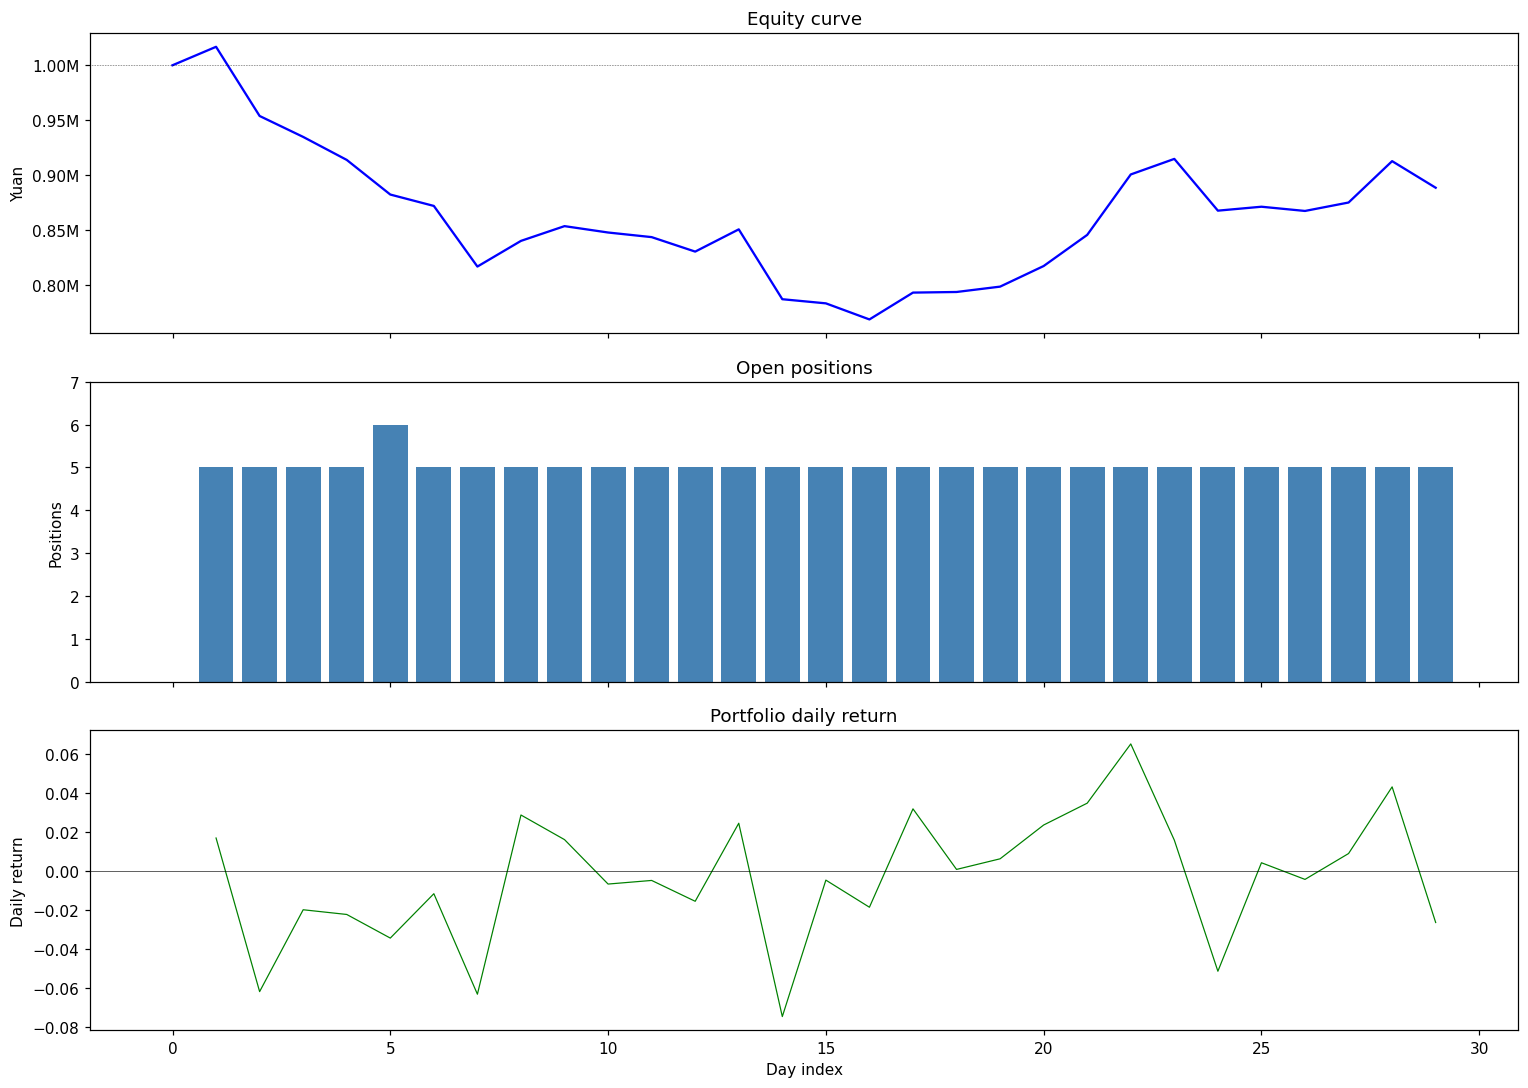

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
x = range(len(held_out))
axes[0].plot(x, equity_hist, lw=1.5, color="blue"); axes[0].axhline(1e6, color="k", lw=0.4, ls=":")
axes[0].set_ylabel("Yuan"); axes[0].set_title("Equity curve")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))
axes[1].bar(x, npos_hist, color="steelblue"); axes[1].set_ylim(0, max(npos_hist)+1)
axes[1].set_ylabel("Positions"); axes[1].set_title("Open positions")
axes[2].plot(x[1:], portfolio_return, lw=0.8, color="green"); axes[2].axhline(0, color="k", lw=0.4)
axes[2].set_ylabel("Daily return"); axes[2].set_xlabel("Day index")
axes[2].set_title("Portfolio daily return")
plt.tight_layout(); plt.show()

## 9b. Why Can Open Positions Exceed 5?

The "Open positions" chart occasionally shows **6** positions even though the
strategy targets 5.  This is **not a bug** — a sell order can go **unfilled**:

* **Limit-down lock**: a held stock hits its board-specific price limit (跌停,
  ±10% main board / ±20% STAR-ChiNext / ±30% BSE).  The `Broker` refuses to sell
  at limit-down, so the position stays a day longer.
* **Volume-participation cap**: a large order may only partially fill, leaving a
  residual position while the re-plan buys a new name.

Simulated data rarely shows the limit-down case (its returns are clipped at
±9.95%), but the participation cap can still cause brief over-holding.

In [15]:
if overhold_days:
    print(f"Days with >5 positions: {len(overhold_days)}")
    for d, n in overhold_days:
        print(f"  {d}: {n} positions (an unfilled sell order left a residual holding)")
else:
    print("No over-holding days in this run.")

Days with >5 positions: 1
  20260715: 6 positions (an unfilled sell order left a residual holding)


## 9a. Cross-Sectional Signal Heatmap

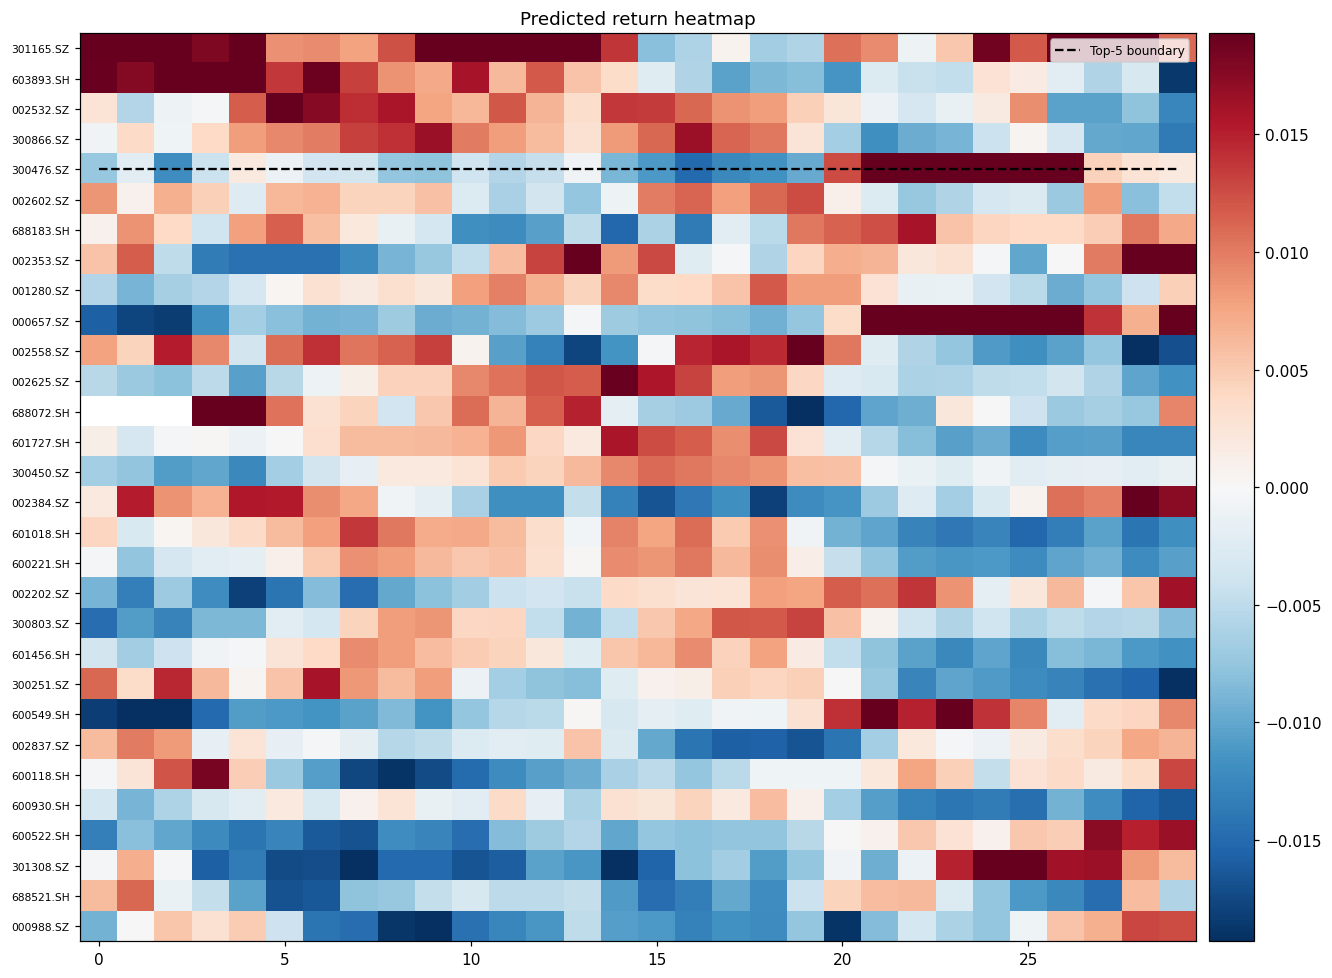

In [16]:
mean_score = np.nanmean(score_matrix, axis=0)
order = np.argsort(-mean_score)
score_ordered = score_matrix[:, order]
syms_ordered = [all_syms[i] for i in order]
fig, ax = plt.subplots(figsize=(13, 9))
vmax = np.nanpercentile(abs(score_ordered), 95)
ax.imshow(score_ordered.T, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
          extent=[-0.5, len(held_out)-0.5, len(all_syms)-0.5, -0.5])
boundary_y = []
for t in range(len(held_out)):
    col = score_ordered[t]; valid = np.where(~np.isnan(col))[0]
    boundary_y.append(valid[4] if valid.size >= 5 else np.nan)
ax.plot(range(len(held_out)), boundary_y, "k--", lw=1.5, label="Top-5 boundary")
ax.set_yticks(range(len(syms_ordered))); ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_title("Predicted return heatmap"); ax.legend(fontsize=8)
fig.colorbar(ax.images[0], ax=ax, pad=0.01)
plt.tight_layout(); plt.show()

## 9b. Position Occupancy Heatmap

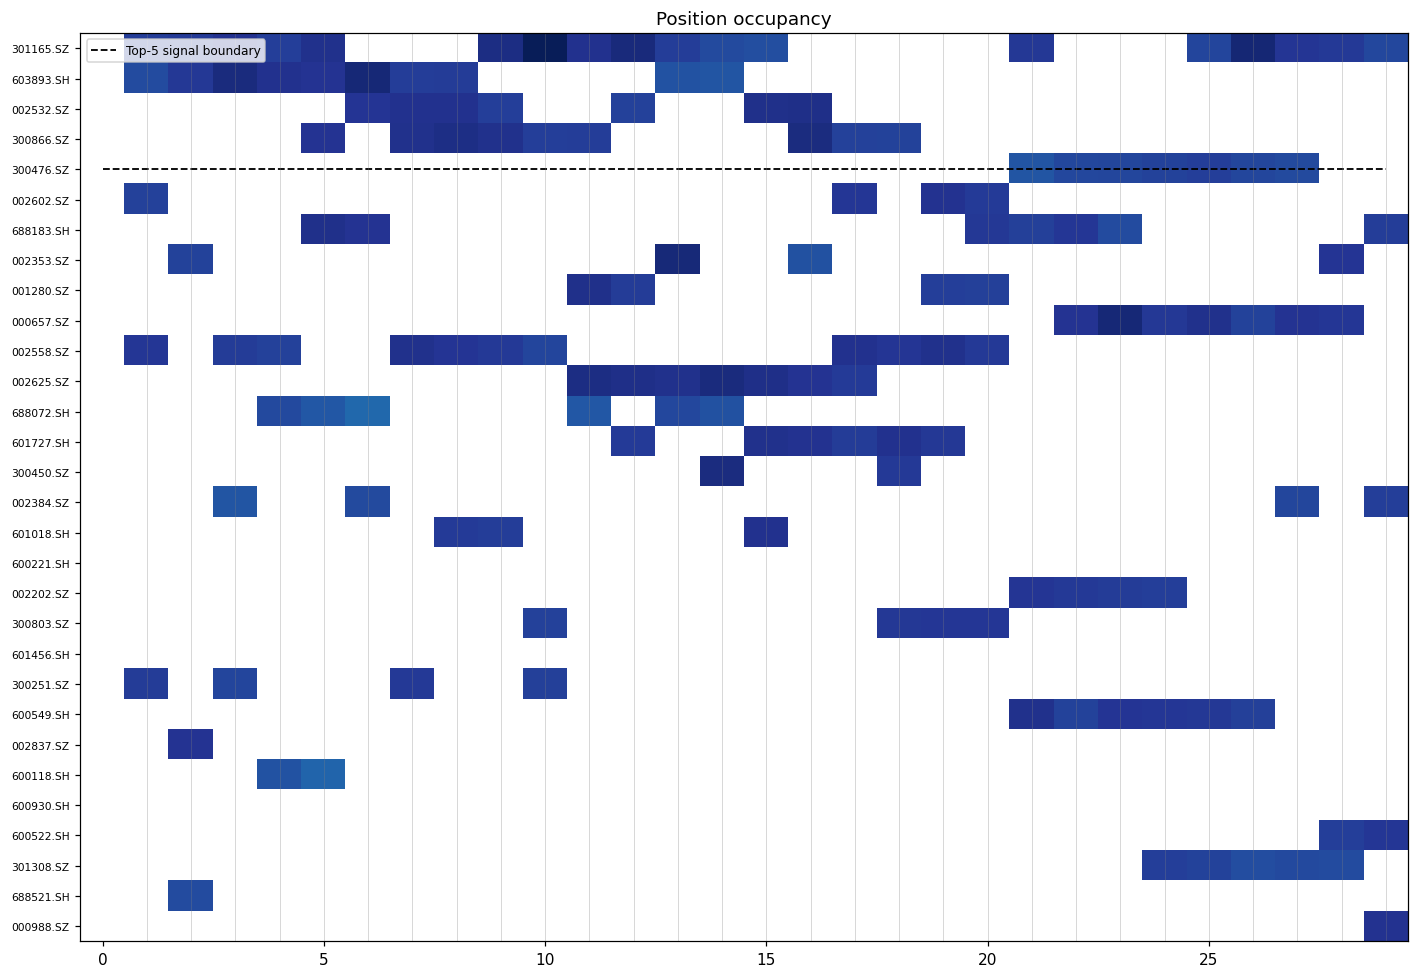

Mean daily weight turnover: 0.7616  (~76.2%/day)
Stocks ever held: 27 / 30


In [17]:
weight_ordered = weight_matrix[:, order]
masked = np.ma.masked_where(weight_ordered.T == 0, weight_ordered.T)
cmap = plt.cm.YlGnBu.copy(); cmap.set_bad(color="white")
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(masked, aspect="auto", cmap=cmap, vmin=0, vmax=max(weight_matrix.max(), 1e-6),
          extent=[-0.5, len(held_out)-0.5, len(all_syms)-0.5, -0.5])
ax.plot(range(len(held_out)), boundary_y, "k--", lw=1.2, label="Top-5 signal boundary")
rebal = [t for t, d in enumerate(held_out) if any(tr.date == d for tr in pm.trades)]
for t in rebal:
    ax.axvline(t, color="gray", lw=0.4, alpha=0.5)
ax.set_yticks(range(len(syms_ordered))); ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_title("Position occupancy"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
turnover = np.abs(np.diff(weight_matrix, axis=0)).sum(axis=1).mean()
print(f"Mean daily weight turnover: {turnover:.4f}  (~{turnover*100:.1f}%/day)")
print(f"Stocks ever held: {int((weight_matrix > 0).any(axis=0).sum())} / {len(all_syms)}")

## 10. Style Exposure

In [18]:
mkt_return = np.array([bars_full[d][uni_full.symbols[0]].market_return for d in held_out[1:]])
X = np.column_stack([np.ones_like(mkt_return), mkt_return])
coeff = np.linalg.lstsq(X, portfolio_return, rcond=None)[0]
print(f"Style exposure:  alpha={coeff[0]:+.5f} ({coeff[0]*252*100:+.2f}% ann), "
      f"beta_market={coeff[1]:+.3f}")

Style exposure:  alpha=-0.00299 (-75.43% ann), beta_market=+0.869


## 11. Short-Index-Futures Hedge

In [19]:
index_start = 5500.0
index_level = np.zeros(len(held_out)); index_level[0] = index_start
cum = 1.0
for t in range(1, len(held_out)):
    cum *= (1.0 + bars_full[held_out[t]][uni_full.symbols[0]].market_return)
    index_level[t] = index_start * cum

hm = HedgeManager(contract=FuturesContract("IM", multiplier=100.0),
                  beta_window=20, min_beta_t=0.0, max_leverage=1.5)
hedge_pnl_hist = []
for t, d in enumerate(held_out):
    pr = portfolio_return[t] if t < len(portfolio_return) else 0.0
    mr = bars_full[d][uni_full.symbols[0]].market_return
    pnl, lots, beta = hm.step(d, equity_hist[t], pr, mr, index_level[t])
    hedge_pnl_hist.append(pnl)
hedged_equity = compute_hedged_equity(equity_hist, [], hedge_pnl_hist)
print(f"Hedge cumulative PnL = {hm.cumulative_pnl:+,.0f} yuan")
print(f"  Raw final: {equity_hist[-1]:,.0f}   Hedged final: {hedged_equity[-1]:,.0f}")

Hedge cumulative PnL = +43,788 yuan
  Raw final: 888,757   Hedged final: 933,932


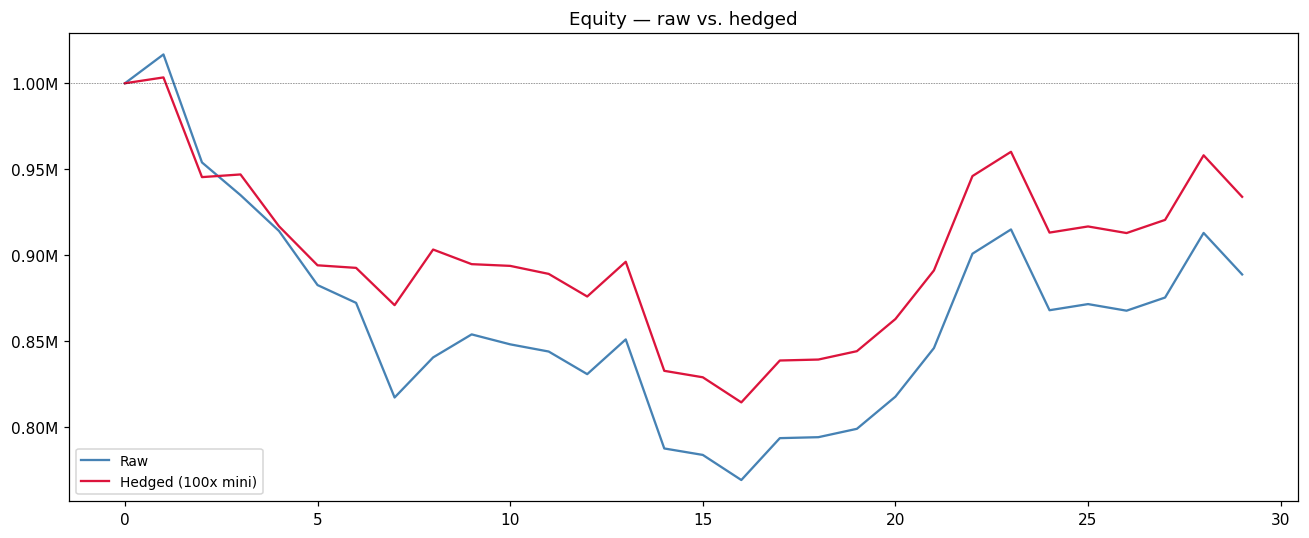

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(range(len(held_out)), equity_hist, lw=1.5, color="steelblue", label="Raw")
ax.plot(range(len(held_out)), hedged_equity, lw=1.5, color="crimson", label="Hedged (100x mini)")
ax.axhline(1e6, color="k", lw=0.4, ls=":"); ax.legend(fontsize=9)
ax.set_title("Equity — raw vs. hedged")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))
plt.tight_layout(); plt.show()

## 12. Risk Management

In [21]:
risk_cfg = RiskConfig(max_weight_per_name=0.25, max_notional_per_trade=200_000,
                      stop_loss_pct=0.08, max_drawdown_pct=0.15, daily_loss_limit_pct=0.03)
pm_risk = PortfolioManager(capital=1_000_000.0, n_holdings=5,
                           aggregator=SignalAggregator(calibration=result),
                           risk_manager=RiskManager(risk_cfg, initial_capital=1_000_000.0))
eng_risk = TradingEngine(factors=factors_full, calibration=result)
trader_risk = Trader(eng_risk, pm_risk, Broker(ExecutionConfig()))
eq_risk = []
for d in held_out:
    trader_risk.step(d, bars_full[d])
    eq_risk.append(pm_risk.portfolio.mark_to_market(bars_full[d]))
print(f"With risk:    {(eq_risk[-1]/1e6-1)*100:+.2f}%  trades={len(pm_risk.trades)}")
print(f"Without risk: {(equity_hist[-1]/1e6-1)*100:+.2f}%  trades={len(pm.trades)}")
risk_trades = [t for t in pm_risk.trades if t.reason in
               ("STOP_LOSS", "TAKE_PROFIT", "MAX_DRAWDOWN", "DAILY_LOSS_LIMIT")]
print(f"Risk-triggered trades: {len(risk_trades)}")

With risk:    -6.33%  trades=22
Without risk: -11.12%  trades=159
Risk-triggered trades: 7


In [22]:
print("=== alftrade demo summary ===")
print(f"Data source:     {DATA_SOURCE}")
print(f"Panel:           {len(uni_full.symbols)} stocks × {len(dates_full)} days")
print(f"Calibration:     Fama-MacBeth, T={result.n_dates}, n={result.sample_size}")
print(f"Model IC:        {model_profile.model_ic:+.4f}")
print(f"Significant:     {model_profile.selected_factors()}")
print(f"Execution:       next-open (slippage {ExecutionConfig().slippage_bps*1e4:.0f} bps + "
      f"half-spread {ExecutionConfig().half_spread_bps*1e4:.0f} bps, "
      f"participation {ExecutionConfig().max_participation*100:.0f}%)")
print(f"Backtest:        {len(held_out)} days, 5 holdings")
print(f"  Without risk:  {(equity_hist[-1]/1e6-1)*100:+.2f}%")
print(f"  With risk:     {(eq_risk[-1]/1e6-1)*100:+.2f}%")

=== alftrade demo summary ===
Data source:     data/real_daily
Panel:           30 stocks × 243 days
Calibration:     Fama-MacBeth, T=98, n=2899
Model IC:        +0.1459
Significant:     ['momentum_5d', 'ma_dev_20', 'atr_pct_14']
Execution:       next-open (slippage 25 bps + half-spread 5 bps, participation 20%)
Backtest:        30 days, 5 holdings
  Without risk:  -11.12%
  With risk:     -6.33%


## 13. Paper Trading Mode (day-by-day simulation)

`PaperTrader` drives the same strategy forward **day by day**, persisting the
account (state.json), an append-only trades ledger, and a markdown report per
day — the no-API substitute for a live account. Here we replay the whole panel
offline; in production ``python -m alftrade.paper`` fetches fresh data and
advances the account by just the new days (cron: workdays 15:35).


In [23]:
import os, tempfile
from alftrade.paper import PaperConfig, PaperTrader, ReplayUpdater
from alftrade import load_ledger

paper_dir = tempfile.mkdtemp(prefix="alftrade_paper_")
paper_cfg = PaperConfig(capital=1_000_000.0, n_holdings=5, pool=STOCK_POOL,
                        state_dir=paper_dir, warmup_days=120)
summary = PaperTrader(paper_cfg, ReplayUpdater(df_full)).run()

print(f"\nState:  {paper_dir}/state.json")
ledger_path = os.path.join(paper_dir, 'trades.csv')
print(f"Ledger: {ledger_path} ({len(load_ledger(ledger_path))} rows)")
reports = sorted(os.listdir(os.path.join(paper_dir, 'reports')))
print(f"Reports: {len(reports)} daily reports — showing the last one:\n")
with open(os.path.join(paper_dir, 'reports', reports[-1])) as f:
    print(f.read())

[paper] days=123, fills=473, rejected=1, partial=0, skipped=9, equity=1,105,538, halted=True, pending=0

State:  /tmp/alftrade_paper_xlzvxa4o/state.json
Ledger: /tmp/alftrade_paper_xlzvxa4o/trades.csv (473 rows)
Reports: 123 daily reports — showing the last one:

# Daily report 20260818

## Account
| | |
|---|---|
| Equity | 1,105,538 |
| Cash | 1,105,538 |
| Day return | +0.00% |
| Realized PnL (all-time) | 105,538 |

## Fills
*No fills today.*

## Order journal
*All orders filled.*

## Fees
| Fee | Amount |
|-----|-------:|
| Commission | 0.00 |
| Transfer | 0.0000 |
| Stamp duty | 0.00 |
| **Total** | **0.00** |

## Positions
*No open positions.*



## 14. Execution Timing — 30-Day Comparison + Mid-Run Switch

Same 30-day walk, three timings.  Then a **manual switch**: start with `open`,
flip to `vwap` halfway through, and see the fill-price basis change.


In [24]:
timings = ["open", "close_auction", "vwap"]
result_eq = {}
for timing in timings:
    pm = PortfolioManager(capital=1_000_000.0, n_holdings=5, weighting="equal",
                          aggregator=SignalAggregator(calibration=result),
                          risk_manager=RiskManager(base_cfg, initial_capital=1_000_000.0))
    trader = Trader(live_engine, pm, Broker(ExecutionConfig(execution_timing=timing)))
    for d in held_out:
        trader.step(d, bars_full[d])
    result_eq[timing] = pm.portfolio.mark_to_market(bars_full[held_out[-1]])
    print(f"{timing:<14} final equity {result_eq[timing]:>12,.0f}  "
          f"({(result_eq[timing]/1e6-1)*100:+.2f}%)  trades={len(pm.trades)}")

# Manual mid-run switch: open -> vwap at the halfway point
pm = PortfolioManager(capital=1_000_000.0, n_holdings=5, weighting="equal",
                      aggregator=SignalAggregator(calibration=result),
                      risk_manager=RiskManager(base_cfg, initial_capital=1_000_000.0))
trader = Trader(live_engine, pm, Broker(ExecutionConfig(execution_timing="open")))
switch_day = held_out[len(held_out) // 2]
print(f"\nSwitching open -> vwap at {switch_day} ...")
for d in held_out:
    fills = trader.step(d, bars_full[d])
    if d == switch_day:
        trader.set_execution_timing("vwap")
    for t in fills:
        bar = bars_full[d][t.symbol]
        ref = bar.open if d <= switch_day else bar.amount / bar.volume
        basis = t.price / ref - 1
        print(f"  {d} {t.symbol} {t.direction:<8} qty={abs(int(t.quantity)):>5} "
              f"fill={t.price:8.2f} ref={ref:8.2f} basis={basis*100:+.2f}%")
print(f"\nFinal equity after mid-run switch: "
      f"{pm.portfolio.mark_to_market(bars_full[held_out[-1]]):,.0f}")


open           final equity      888,757  (-11.12%)  trades=159
close_auction  final equity      836,764  (-16.32%)  trades=158
vwap           final equity      841,944  (-15.81%)  trades=161

Switching open -> vwap at 20260729 ...
  20260709 301165.SZ OPEN     qty= 1800 fill=  103.26 ref=  102.95 basis=+0.30%
  20260709 603893.SH OPEN     qty=  900 fill=  202.93 ref=  202.32 basis=+0.30%
  20260709 300251.SZ OPEN     qty=16100 fill=   12.19 ref=   12.15 basis=+0.33%
  20260709 002602.SZ OPEN     qty=14000 fill=   14.15 ref=   14.11 basis=+0.28%
  20260709 002558.SZ OPEN     qty= 7100 fill=   27.63 ref=   27.55 basis=+0.29%
  20260710 300251.SZ CLOSE    qty=16100 fill=   12.16 ref=   12.20 basis=-0.33%
  20260710 002602.SZ CLOSE    qty=14000 fill=   13.73 ref=   13.77 basis=-0.29%
  20260710 002558.SZ CLOSE    qty= 7100 fill=   27.82 ref=   27.90 basis=-0.29%
  20260710 002353.SZ OPEN     qty= 1200 fill=  170.51 ref=  170.00 basis=+0.30%
  20260710 688521.SH OPEN     qty=  600 fill=  3